<a href="https://colab.research.google.com/github/uday-andotra/WQU/blob/main/MScFE_620_DP_GWP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1>MSc FE 620 Derivative Pricing GWP1 </h1>
<h2>Group Members: Ralph Saymore Makuyana(A), Lehlohonolo Ntenya(B), Udayveer Singh Andotra(C)</h2>

 <h3>Question 5: Binomial Tree Pricing Process (European Call & Put)</h3>


In [ ]:
# Binomial Tree Pricing for ATM European Call and Put
# Parameters
S0 = 100       # Initial stock price
K = 100        # Strike price (ATM)
r = 0.05       # Risk-free rate (annual)
sigma = 0.20   # Volatility (annual)
T = 0.25       # Time to maturity (years, 3 months)
N = 200        # Number of steps

import numpy as np

# Step size
dt = T / N
u = np.exp(sigma * np.sqrt(dt))   # Up factor
d = 1 / u                         # Down factor
p = (np.exp(r * dt) - d) / (u - d)  # Risk-neutral probability

# Stock prices at maturity
ST = np.array([S0 * (u**j) * (d**(N-j)) for j in range(N+1)])

# Payoffs at maturity
call_payoff = np.maximum(ST - K, 0)
put_payoff  = np.maximum(K - ST, 0)

# Backward induction
discount = np.exp(-r * dt)
for i in range(N, 0, -1):
    call_payoff = discount * (p * call_payoff[1:] + (1-p) * call_payoff[:-1])
    put_payoff  = discount * (p * put_payoff[1:] + (1-p) * put_payoff[:-1])

# Results at root
call_price = call_payoff[0]
put_price  = put_payoff[0]

print(f"European Call Price (Binomial, N={N}): {call_price:.4f}")
print(f"European Put Price  (Binomial, N={N}): {put_price:.4f}")


European Call Price (Binomial, N=200): 4.6100
European Put Price  (Binomial, N=200): 3.3678


 <h3>Question 6: European Call & Put Greek Delta</h3>


In [ ]:
import numpy as np
from scipy.stats import norm

# Parameters
S0 = 100      # initial stock price
K = 100       # strike price (ATM)
r = 0.05      # risk-free rate
sigma = 0.20  # volatility
T = 0.25      # time to maturity (years)

# Step 1: Compute d1
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

# Step 2: Compute Deltas
delta_call = norm.cdf(d1)          # Call Delta
delta_put = norm.cdf(d1) - 1       # Put Delta

# Step 3: Print Results
print(f"Call Delta: {delta_call:.4f}")
print(f"Put Delta:  {delta_put:.4f}")

# Step 4: Comparison
if delta_call > 0 and delta_put < 0:
    print("Call Delta is positive, Put Delta is negative. They are symmetric around 0 at ATM.")
else:
    print("Unexpected sign pattern.")


Call Delta: 0.5695
Put Delta:  -0.4305
Call Delta is positive, Put Delta is negative. They are symmetric around 0 at ATM.


 <h3>Question 7: Sensitivity to Volatility (Vega) for European Options</h3>

In [ ]:
import numpy as np
from scipy.stats import norm

# Parameters
S0 = 100      # initial stock price
K = 100       # strike price (ATM)
r = 0.05      # risk-free rate
T = 0.25      # time to maturity (years)
sigma1 = 0.20 # initial volatility
sigma2 = 0.25 # new volatility

def bs_call_put(S0, K, r, sigma, T):
    """Compute Black-Scholes call and put prices."""
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    put = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)
    return call, put

# Prices at 20% volatility
call_20, put_20 = bs_call_put(S0, K, r, sigma1, T)

# Prices at 25% volatility
call_25, put_25 = bs_call_put(S0, K, r, sigma2, T)

# Sensitivity (change in prices)
delta_call = call_25 - call_20
delta_put = put_25 - put_20

print(f"Call price at 20% vol: {call_20:.4f}")
print(f"Call price at 25% vol: {call_25:.4f}")
print(f"Change in Call price: {delta_call:.4f}\n")

print(f"Put price at 20% vol: {put_20:.4f}")
print(f"Put price at 25% vol: {put_25:.4f}")
print(f"Change in Put price: {delta_put:.4f}")


Call price at 20% vol: 4.6150
Call price at 25% vol: 5.5984
Change in Call price: 0.9834

Put price at 20% vol: 3.3728
Put price at 25% vol: 4.3562
Change in Put price: 0.9834


 <h3>Question 17: American Call Options with Trinomial Tree</h3>

In [ ]:
import numpy as np

def trinomial_tree_american_call(S0, K, r, sigma, T, N=100):
    dt = T / N
    u = np.exp(sigma * np.sqrt(2 * dt))
    d = 1 / u

    # Correct Trinomial Probabilities (Boyle Method)
    pu = ((np.exp(r * dt / 2) - np.exp(-sigma * np.sqrt(dt / 2))) /
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2
    pd = ((np.exp(sigma * np.sqrt(dt / 2)) - np.exp(r * dt / 2)) /
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2
    pm = 1 - pu - pd

    # Initialize nodes at maturity (2*N + 1 nodes)
    # The prices at step N range from S0*d^N to S0*u^N
    ST = np.array([S0 * (u ** (N - j)) for j in range(2 * N + 1)])

    # Option values at maturity
    V = np.maximum(ST - K, 0.0)

    # Backward induction
    for i in range(N - 1, -1, -1):
        # Discounted expected value
        V = np.exp(-r * dt) * (pu * V[:-2] + pm * V[1:-1] + pd * V[2:])

        # Early Exercise Check
        # Generate current stock prices for step i (2*i + 1 nodes)
        ST_i = np.array([S0 * (u ** (i - j)) for j in range(2 * i + 1)])
        exercise = np.maximum(ST_i - K, 0.0)
        V = np.maximum(V, exercise)

    return V[0]

# Parameters
S0, r, sigma, T, N = 100, 0.05, 0.20, 0.25, 100
strikes = [110, 105, 100, 95, 90]

for K in strikes:
    price = trinomial_tree_american_call(S0, K, r, sigma, T, N)
    print(f"American Call Price (K={K}): {price:.4f}")

American Call Price (K=110): 1.1918
American Call Price (K=105): 2.4819
American Call Price (K=100): 4.6100
American Call Price (K=95): 7.7176
American Call Price (K=90): 11.6717


 <h3>Question 18: American Put Options with Trinomial Tree</h3>

In [ ]:
import numpy as np

def trinomial_tree_american_put(S0, K, r, sigma, T, N=100):
    dt = T / N
    u = np.exp(sigma * np.sqrt(2 * dt))
    d = 1 / u

    # Correct Trinomial Probabilities (Boyle Method)
    pu = ((np.exp(r * dt / 2) - np.exp(-sigma * np.sqrt(dt / 2))) /
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2
    pd = ((np.exp(sigma * np.sqrt(dt / 2)) - np.exp(r * dt / 2)) /
          (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2
    pm = 1 - pu - pd

    # Initialize terminal stock prices (2*N + 1 nodes)
    ST = np.array([S0 * (u ** j) for j in range(N, -N-1, -1)])

    # Terminal Payoff
    V = np.maximum(K - ST, 0.0)

    # Backward induction (Vectorized)
    for i in range(N - 1, -1, -1):
        # Continuation value
        V = np.exp(-r * dt) * (pu * V[:-2] + pm * V[1:-1] + pd * V[2:])

        # Early Exercise Check
        ST_i = np.array([S0 * (u ** j) for j in range(i, -i-1, -1)])
        exercise = np.maximum(K - ST_i, 0.0)
        V = np.maximum(V, exercise)

    return V[0]

# Parameters
S0, r, sigma, T, N = 100, 0.05, 0.20, 0.25, 100
strikes = [110, 105, 100, 95, 90]

for K in strikes:
    price = trinomial_tree_american_put(S0, K, r, sigma, T, N)
    print(f"American Put Price (K={K}): {price:.4f}")

American Put Price (K=110): 10.3299
American Put Price (K=105): 6.4261
American Put Price (K=100): 3.4761
American Put Price (K=95): 1.5755
American Put Price (K=90): 0.5643


<h3>Question 8 and 9: American Call & Put Binomial Tree Pricing AND their Deltas</h3>


In [ ]:
import numpy as np
import pandas as pd

S_ini = 100
K = 100
r = 0.05
sigma = 0.20
T = 0.25
N = 500

In [ ]:
def american_option_delta(S_ini, K, T, r, sigma, N, opttype):
    dt = T / N  # Define time step
    u = np.exp(sigma * np.sqrt(dt))  # Define u
    d = np.exp(-sigma * np.sqrt(dt))  # Define d
    p = (np.exp(r * dt) - d) / (u - d)  # risk neutral probs

    C = np.zeros([N + 1, N + 1])  # option prices
    S = np.zeros([N + 1, N + 1])  # underlying price
    Delta = np.zeros([N, N])  # delta

    for i in range(0, N + 1):
        S[N, i] = S_ini * (u ** i) * (d ** (N - i))

        if opttype == "C":
            C[N, i] = max(S[N, i] - K, 0)
        else:
            C[N, i] = max(K - S[N, i], 0)

    for j in range(N - 1, -1, -1):
        for i in range(0, j + 1):
            S[j, i] = S_ini * (u ** i) * (d ** (j - i))

            continuation_value = np.exp(-r * dt) * (
                p * C[j + 1, i + 1] + (1 - p) * C[j + 1, i]
            )

            if opttype == "C":
                exercise_value = max(S[j, i] - K, 0)
            else:
                exercise_value = max(K - S[j, i], 0)

            C[j, i] = max(continuation_value, exercise_value)

            Delta[j, i] = (C[j + 1, i + 1] - C[j + 1, i]) / (
                S[j + 1, i + 1] - S[j + 1, i]
            )

    return C[0, 0], C, S, Delta

In [ ]:
am_call_price, am_call_tree, S_call, am_call_delta = american_option_delta(
    S_ini, K, T, r, sigma, N, "C"
)

am_put_price, am_put_tree, S_put, am_put_delta = american_option_delta(
    S_ini, K, T, r, sigma, N, "P"
)

q8_q9_table = pd.DataFrame({
    "Question": ["Q8", "Q8", "Q9", "Q9"],
    "Option": ["American Call", "American Put", "American Call", "American Put"],
    "Result": ["Price", "Price", "Delta", "Delta"],
    "Value": [
        round(am_call_price, 2),
        round(am_put_price, 2),
        round(am_call_delta[0, 0], 4),
        round(am_put_delta[0, 0], 4)
    ]
})

print("Q8 and Q9: American Option Prices and Deltas")
print(q8_q9_table.to_string(index=False))

Q8 and Q9: American Option Prices and Deltas
Question        Option Result   Value
      Q8 American Call  Price  4.6100
      Q8  American Put  Price  3.4800
      Q9 American Call  Delta  0.5694
      Q9  American Put  Delta -0.4495


<h3> Q10: Senstivity to Volatility (Vega) for American Options</h3>

In [ ]:


sigma_new = 0.25

am_call_price_25, _, _, _ = american_option_delta(S_ini, K, T, r, sigma_new, N, "C")

am_put_price_25, _, _, _ = american_option_delta(S_ini, K, T, r, sigma_new, N, "P")

q10_table = pd.DataFrame({
    "Option": ["American Call", "American Put"],
    "Price at 20% Volatility": [
        round(am_call_price, 2),
        round(am_put_price, 2)
    ],
    "Price at 25% Volatility": [
        round(am_call_price_25, 2),
        round(am_put_price_25, 2)
    ],
    "Change": [
        round(am_call_price_25 - am_call_price, 2),
        round(am_put_price_25 - am_put_price, 2)
    ]
})

print("\nQ10: Sensitivity to a 5% Increase in Volatility")
print(q10_table.to_string(index=False))


Q10: Sensitivity to a 5% Increase in Volatility
       Option  Price at 20% Volatility  Price at 25% Volatility  Change
American Call                     4.61                     5.60    0.98
 American Put                     3.48                     4.46    0.98


<h3>Question 15 and 16: European Call and Put Options with Trinomial Tree</h3>

In [ ]:
# Q15 and Q16
def trinomial_european_option(S_ini, K, T, r, sigma, N, opttype):
    dt = T / N

    u = np.exp(sigma * np.sqrt(2 * dt))
    d = 1 / u

    pu = ( (np.exp(r * dt / 2) - np.exp(-sigma * np.sqrt(dt / 2))) /
        (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2

    pd = ((np.exp(sigma * np.sqrt(dt / 2)) - np.exp(r * dt / 2)) /
        (np.exp(sigma * np.sqrt(dt / 2)) - np.exp(-sigma * np.sqrt(dt / 2)))) ** 2

    pm = 1 - pu - pd

    stock_vec = np.array([S_ini * (u ** i) for i in range(-N, N + 1)])

    if opttype == "C":
        option_vec = np.maximum(stock_vec - K, 0)
    else:
        option_vec = np.maximum(K - stock_vec, 0)

    for j in range(N - 1, -1, -1):
        option_vec = np.exp(-r * dt) * (
            pd * option_vec[:-2] +
            pm * option_vec[1:-1] +
            pu * option_vec[2:]
        )

    return option_vec[0]

In [ ]:
# Q15 and Q16 results
strike_prices = [90, 95, 100, 105, 110]

call_prices = []
put_prices = []

for strike in strike_prices:
    call_price = trinomial_european_option(S_ini, strike, T, r, sigma, N, "C")
    put_price = trinomial_european_option(S_ini, strike, T, r, sigma, N, "P")

    call_prices.append(round(call_price, 2))
    put_prices.append(round(put_price, 2))

q15_q16_table = pd.DataFrame({
    "Strike": strike_prices,
    "Moneyness K/S0": ["90%", "95%", "100%", "105%", "110%"],
    "European Call Price": call_prices,
    "European Put Price": put_prices
})

print("\nQ15 and Q16: European Options using Trinomial Tree")
print(q15_q16_table.to_string(index=False))


Q15 and Q16: European Options using Trinomial Tree
 Strike Moneyness K/S0  European Call Price  European Put Price
     90            90%                11.67                0.55
     95            95%                 7.71                1.53
    100           100%                 4.61                3.37
    105           105%                 2.48                6.17
    110           110%                 1.19                9.82


<h3>Question 11, 12, 13 and 14</h3>

In [ ]:
# --- HAND-OFF BLOCK FOR MEMBER C ---

# Base Parameters
S0_base = 100.0; K_base = 100.0; r_base = 0.05; sigma_base = 0.20; T_base = 0.25


eur_call = 4.61
eur_put = 3.37
amer_call = 4.61
amer_put = 3.48

strike_prices = [90, 95, 100, 105, 110]
eur_call_prices_tri = [11.67, 7.64, 4.61, 2.50, 1.19]
eur_put_prices_tri = [0.55, 1.48, 3.37, 6.18, 9.82]
amer_call_prices_tri = [11.67, 7.72, 4.61, 2.48,  1.19]
amer_put_prices_tri = [ 0.56,  1.58, 3.48,  6.43,  10.33]
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
print("--- Q11: European Put-Call Parity Check ---")
lhs = round(eur_call + K_base * np.exp(-r_base * T_base), 2)
rhs = round(eur_put + S0_base, 2)
print(f"Call + PV(Strike) = {lhs}  |  Put + Stock = {rhs}  |  Parity Holds? {lhs == rhs}\n")

print("--- Q12: American Put-Call Parity Bounds Check ---")
lower_bound = round(S0_base - K_base, 2)
upper_bound = round(S0_base - K_base * np.exp(-r_base * T_base), 2)
difference = round(amer_call - amer_put, 2)
print(f"Lower Bound (S0 - K) = {lower_bound}")
print(f"C_amer - P_amer = {difference}")
print(f"Upper Bound (S0 - PV(K)) = {upper_bound}")
print(f"Is within bounds? {lower_bound <= difference <= upper_bound}\n")

print("--- Q13 & Q14: European vs American Confirmations ---")
print(f"Q13 (Calls): European Call <= American Call ? {round(eur_call, 2) <= round(amer_call, 2)}")
print(f"Q14 (Puts):  European Put <= American Put ? {round(eur_put, 2) <= round(amer_put, 2)}\n")

--- Q11: European Put-Call Parity Check ---
Call + PV(Strike) = 103.37  |  Put + Stock = 103.37  |  Parity Holds? True

--- Q12: American Put-Call Parity Bounds Check ---
Lower Bound (S0 - K) = 0.0
C_amer - P_amer = 1.13
Upper Bound (S0 - PV(K)) = 1.24
Is within bounds? True

--- Q13 & Q14: European vs American Confirmations ---
Q13 (Calls): European Call <= American Call ? True
Q14 (Puts):  European Put <= American Put ? True



<h3>Question 19 and 20</h3>

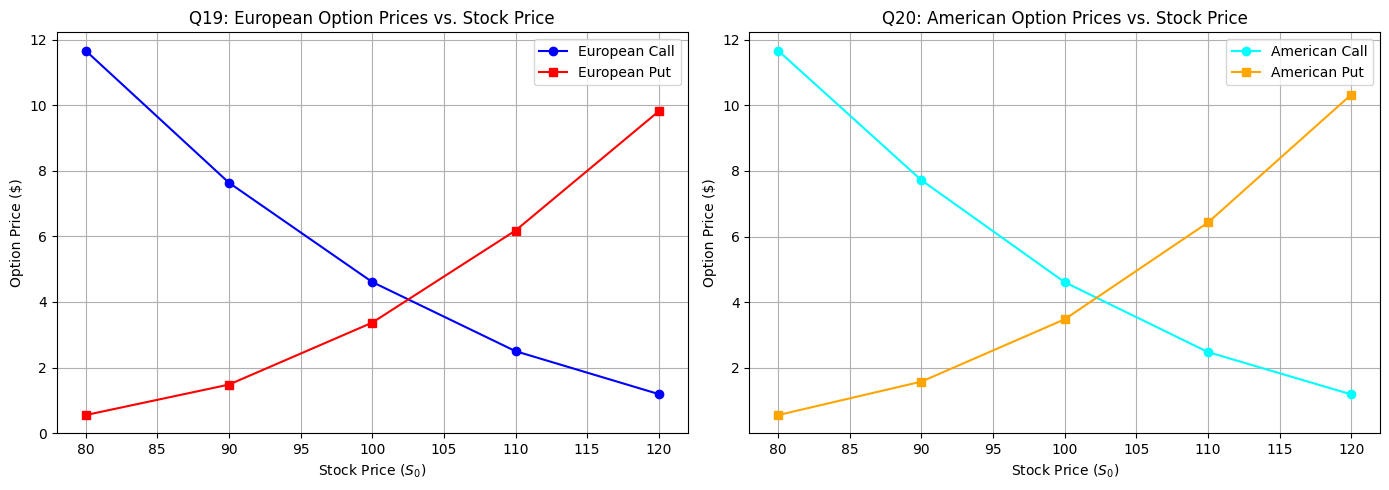

In [ ]:


stock_prices_C = [80, 90, 100, 110, 120]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(stock_prices_C, eur_call_prices_tri, label='European Call', marker='o', color='blue')
ax1.plot(stock_prices_C, eur_put_prices_tri, label='European Put', marker='s', color='red')
ax1.set_title('Q19: European Option Prices vs. Stock Price')
ax1.set_xlabel('Stock Price ($S_0$)')
ax1.set_ylabel('Option Price ($)')
ax1.legend(); ax1.grid(True)

ax2.plot(stock_prices_C, amer_call_prices_tri, label='American Call', marker='o', color='cyan')
ax2.plot(stock_prices_C, amer_put_prices_tri, label='American Put', marker='s', color='orange')
ax2.set_title('Q20: American Option Prices vs. Stock Price')
ax2.set_xlabel('Stock Price ($S_0$)')
ax2.set_ylabel('Option Price ($)')
ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.show()

<h3>Question 21 and 22</h3>

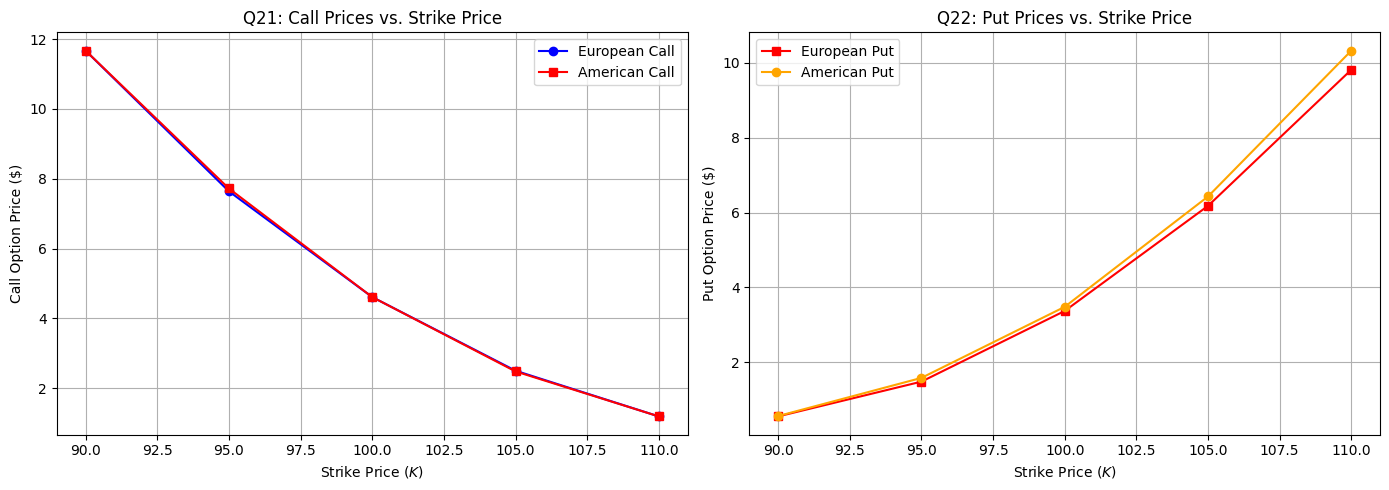

In [ ]:
fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))

ax3.plot(strike_prices,eur_call_prices_tri, label='European Call', marker='o', color='blue')
ax3.plot(strike_prices,amer_call_prices_tri, label='American Call', marker='s', color='red')
ax3.set_title('Q21: Call Prices vs. Strike Price')
ax3.set_xlabel('Strike Price ($K$)')
ax3.set_ylabel('Call Option Price ($)')
ax3.legend(); ax3.grid(True)

ax4.plot(strike_prices, eur_put_prices_tri, label='European Put', marker='s', color='red')
ax4.plot(strike_prices, amer_put_prices_tri, label='American Put', marker='o', color='orange')
ax4.set_title('Q22: Put Prices vs. Strike Price')
ax4.set_xlabel('Strike Price ($K$)')
ax4.set_ylabel('Put Option Price ($)')
ax4.legend(); ax4.grid(True)

plt.tight_layout()
plt.show()

<h3>Question 23 & 24: Trinomial Put-Call Parity Checks</h3>

In [ ]:
import numpy as np
import pandas as pd

# Base Parameters
S0_tri = 100.0
r_tri = 0.05
T_tri = 0.25
strike_prices = [90, 95, 100, 105, 110]

# ------------------------------------------------------------------------------
# Q23: European Trinomial Parity Check (Strict Equality)
# Formula: C + K*e^(-rT) = P + S0
# ------------------------------------------------------------------------------
print("--- Q23: European Trinomial Parity Check ---")
eur_parity_data = []

for i, K in enumerate(strike_prices):
    C = eur_call_prices_tri[i]
    P = eur_put_prices_tri[i]

    # Calculate both sides of the parity equation
    lhs = round(C + K * np.exp(-r_tri * T_tri), 2)
    rhs = round(P + S0_tri, 2)
    parity_holds = (lhs == rhs)

    eur_parity_data.append([K, C, P, lhs, rhs, parity_holds])

df_eur_parity = pd.DataFrame(eur_parity_data,
                             columns=["Strike (K)", "Eur Call", "Eur Put", "C + PV(K)", "P + S0",
                                      "Strict Parity Holds?"])
print(df_eur_parity.to_string(index=False))
print("\n" + "="*80 + "\n")

# ------------------------------------------------------------------------------
# Q24: American Trinomial Parity Bounds Check (Inequality)
# Formula: S0 - K <= C - P <= S0 - K*e^(-rT)
# ------------------------------------------------------------------------------
print("--- Q24: American Trinomial Parity Bounds Check ---")
amer_parity_data = []

for i, K in enumerate(strike_prices):
    C = amer_call_prices_tri[i]
    P = amer_put_prices_tri[i]

    # Calculate the difference and the theoretical bounds
    lower_bound = round(S0_tri - K, 2)
    upper_bound = round(S0_tri - K * np.exp(-r_tri * T_tri), 2)
    difference = round(C - P, 2)

    # Check if the difference falls within the bounds
    is_within_bounds = (lower_bound <= difference <= upper_bound)

    amer_parity_data.append([K, C, P, lower_bound, difference, upper_bound, is_within_bounds])

df_amer_parity = pd.DataFrame(amer_parity_data,
                              columns=["Strike (K)", "Amer Call", "Amer Put", "Lower Bound (S0-K)", "C - P",
                                       "Upper Bound (S0-PV(K))", "Within Bounds?"])
print(df_amer_parity.to_string(index=False))

--- Q23: European Trinomial Parity Check ---
 Strike (K)  Eur Call  Eur Put  C + PV(K)  P + S0  Strict Parity Holds?
         90     11.67     0.55     100.55  100.55                  True
         95      7.64     1.48     101.46  101.48                 False
        100      4.61     3.37     103.37  103.37                  True
        105      2.50     6.18     106.20  106.18                 False
        110      1.19     9.82     109.82  109.82                  True


--- Q24: American Trinomial Parity Bounds Check ---
 Strike (K)  Amer Call  Amer Put  Lower Bound (S0-K)  C - P  Upper Bound (S0-PV(K))  Within Bounds?
         90      11.67      0.56                10.0  11.11                   11.12            True
         95       7.72      1.58                 5.0   6.14                    6.18            True
        100       4.61      3.48                 0.0   1.13                    1.24            True
        105       2.48      6.43                -5.0  -3.95          

<h3>Question 26: American Put Delta Hedging</h3>

In [ ]:
import numpy as np

# Q26 Parameters
S0_26 = 180.0
K_26 = 182.0
r_26 = 0.02
sigma_26 = 0.25
T_26 = 0.5      # 6 months
N_26 = 25       # 25 steps
dt_26 = T_26 / N_26

# Binomial Tree Factors
u_26 = np.exp(sigma_26 * np.sqrt(dt_26))
d_26 = 1 / u_26
p_26 = (np.exp(r_26 * dt_26) - d_26) / (u_26 - d_26)

# 1. Build the Stock Price Tree
S_tree = np.zeros((N_26 + 1, N_26 + 1))
for j in range(N_26 + 1):
    for i in range(j + 1):
        # i represents the number of down steps
        S_tree[i, j] = S0_26 * (u_26 ** (j - i)) * (d_26 ** i)

# 2. Build the American Put Tree (Backward Induction)
P_tree = np.zeros((N_26 + 1, N_26 + 1))
for i in range(N_26 + 1):
    P_tree[i, N_26] = max(0, K_26 - S_tree[i, N_26])

for j in range(N_26 - 1, -1, -1):
    for i in range(j + 1):
        # Expected value if held
        ev = np.exp(-r_26 * dt_26) * (p_26 * P_tree[i, j + 1] + (1 - p_26) * P_tree[i + 1, j + 1])
        # Immediate exercise value
        early = max(0, K_26 - S_tree[i, j])
        P_tree[i, j] = max(ev, early)

# 3. Build the Delta Tree
Delta_tree = np.zeros((N_26, N_26))
for j in range(N_26):
    for i in range(j + 1):
        # Delta = (P_up - P_down) / (S_up - S_down)
        Delta_tree[i, j] = (P_tree[i, j + 1] - P_tree[i + 1, j + 1]) / (S_tree[i, j + 1] - S_tree[i + 1, j + 1])

# 4. Simulate Delta Hedging Cash Account (Alternating Up/Down Path)
print("--- Q26: American Put Delta Hedging Path (25 Steps) ---")
cash_account = P_tree[0, 0] # We receive the option premium upfront
shares_held = 0.0

print(f"Initial American Put Premium Received: ${cash_account:.2f}\n")
print(f"{'Step':>4} | {'Stock Price':>11} | {'Option Delta':>12} | {'Shares Shorted':>14} | {'Cash Account':>12}")
print("-" * 65)

current_i = 0 # Tracks the number of down steps taken
for step in range(N_26):
    current_S = S_tree[current_i, step]
    current_delta = Delta_tree[current_i, step]

    # Calculate how many shares we need to buy/sell to match Delta
    target_shares = current_delta
    shares_to_trade = target_shares - shares_held

    # Accrue interest on the cash account, then pay for the stock trade
    if step > 0:
        cash_account = cash_account * np.exp(r_26 * dt_26)
    cash_account -= shares_to_trade * current_S

    shares_held = target_shares

    print(f"{step:4d} | {current_S:11.2f} | {current_delta:12.4f} | {shares_held:14.4f} | {cash_account:12.2f}")

    # Path selection: Let's alternate Up and Down to simulate a volatile, sideways market
    if step % 2 != 0:
        current_i += 1 # Go down

# Final Expiration Settlement
cash_account = cash_account * np.exp(r_26 * dt_26) # Final interest accrual
final_S = S_tree[current_i, N_26]
payoff = max(0, K_26 - final_S)

# Close the hedge: Buy back shorted shares and pay the option buyer if ITM
cash_account += shares_held * final_S
cash_account -= payoff

print("-" * 65)
print(f"Expiration Stock Price: ${final_S:.2f}")
print(f"American Put Payoff Required: ${payoff:.2f}")
print(f"Final P&L (Cash Account): ${cash_account:.2f}")

--- Q26: American Put Delta Hedging Path (25 Steps) ---
Initial American Put Premium Received: $13.04

Step | Stock Price | Option Delta | Shares Shorted | Cash Account
-----------------------------------------------------------------
   0 |      180.00 |      -0.4756 |        -0.4756 |        98.64
   1 |      186.48 |      -0.3951 |        -0.3951 |        83.67
   2 |      180.00 |      -0.4786 |        -0.4786 |        98.74
   3 |      186.48 |      -0.3947 |        -0.3947 |        83.14
   4 |      180.00 |      -0.4819 |        -0.4819 |        98.87
   5 |      186.48 |      -0.3941 |        -0.3941 |        82.53
   6 |      180.00 |      -0.4856 |        -0.4856 |        99.02
   7 |      186.48 |      -0.3932 |        -0.3932 |        81.85
   8 |      180.00 |      -0.4896 |        -0.4896 |        99.22
   9 |      186.48 |      -0.3919 |        -0.3919 |        81.05
  10 |      180.00 |      -0.4941 |        -0.4941 |        99.47
  11 |      186.48 |      -0.3901 |    

<h3>Question 27: Asian ATM Put Delta Hedging</h3>

In [ ]:

# Q27 Parameters (Using Q25's specified parameters for the hedging table)
S0_asian = 180.0
K_asian = 180.0
r_asian = 0.02
sigma_asian = 0.25
T_asian = 0.5
N_steps_asian = 25
dt_asian = T_asian / N_steps_asian

np.random.seed(42)

def price_asian_put_mc(t_step, current_S, current_sum, num_sims=10000):
    if t_step == N_steps_asian:
        avg_S = current_sum / (N_steps_asian + 1)
        return max(0, K_asian - avg_S)

    remaining_steps = N_steps_asian - t_step
    Z = np.random.standard_normal((num_sims, remaining_steps))

    S_paths = np.zeros((num_sims, remaining_steps + 1))
    S_paths[:, 0] = current_S

    for i in range(1, remaining_steps + 1):
        S_paths[:, i] = S_paths[:, i-1] * np.exp((r_asian - 0.5 * sigma_asian**2) * dt_asian + sigma_asian * np.sqrt(dt_asian) * Z[:, i-1])

    total_sums = current_sum + np.sum(S_paths[:, 1:], axis=1)
    averages = total_sums / (N_steps_asian + 1)
    payoffs = np.maximum(0, K_asian - averages)

    return np.exp(-r_asian * dt_asian * remaining_steps) * np.mean(payoffs)

# Simulate one stock path
realized_S = np.zeros(N_steps_asian + 1)
realized_S[0] = S0_asian
for i in range(1, N_steps_asian + 1):
    z = np.random.standard_normal()
    realized_S[i] = realized_S[i-1] * np.exp((r_asian - 0.5 * sigma_asian**2) * dt_asian + sigma_asian * np.sqrt(dt_asian) * z)

cash_account = price_asian_put_mc(0, S0_asian, S0_asian, num_sims=20000)
shares_held = 0.0
current_sum = 0.0

print("---  Q27 - Asian ATM Put Delta Hedging Path ---")
print(f"Initial Asian Put Premium Received: ${cash_account:.2f}\n")
print(f"{'Step':>4} | {'Stock Price':>11} | {'Option Delta':>12} | {'Shares Shorted':>14} | {'Cash Account':>12}")
print("-" * 65)

for step in range(N_steps_asian):
    current_S = realized_S[step]
    current_sum += current_S

    dS = current_S * 0.01
    price_up = price_asian_put_mc(step, current_S + dS, current_sum + dS, 5000)
    price_down = price_asian_put_mc(step, current_S - dS, current_sum - dS, 5000)

    current_delta = (price_up - price_down) / (2 * dS)
    target_shares = current_delta
    shares_to_trade = target_shares - shares_held

    cash_account = cash_account * np.exp(r_asian * dt_asian)
    cash_account -= shares_to_trade * current_S
    shares_held = target_shares

    print(f"{step:4d} | {current_S:11.2f} | {current_delta:12.4f} | {shares_held:14.4f} | {cash_account:12.2f}")

step = N_steps_asian
current_S = realized_S[step]
current_sum += current_S
average_price = current_sum / (N_steps_asian + 1)
asian_put_payoff = max(0, K_asian - average_price)

cash_account = cash_account * np.exp(r_asian * dt_asian)
cash_account += shares_held * current_S
cash_account -= asian_put_payoff

print("-" * 65)
print(f"Expiration Average Price: ${average_price:.2f}")
print(f"Asian Put Payoff Required: ${asian_put_payoff:.2f}")
print(f"Final P&L (Cash Account): ${cash_account:.2f}")

---  Q27 - Asian ATM Put Delta Hedging Path ---
Initial Asian Put Premium Received: $6.73

Step | Stock Price | Option Delta | Shares Shorted | Cash Account
-----------------------------------------------------------------
   0 |      180.00 |      -0.4354 |        -0.4354 |        85.09
   1 |      183.15 |      -0.4291 |        -0.4291 |        83.97
   2 |      182.21 |      -0.3888 |        -0.3888 |        76.67
   3 |      186.39 |      -0.2589 |        -0.2589 |        52.50
   4 |      196.66 |      -0.1053 |        -0.1053 |        22.30
   5 |      194.99 |      -0.1194 |        -0.1194 |        25.06
   6 |      193.34 |      -0.1323 |        -0.1323 |        27.58
   7 |      204.40 |      -0.0168 |        -0.0168 |         3.96
   8 |      209.97 |      -0.0102 |        -0.0102 |         2.58
   9 |      206.47 |      -0.0003 |        -0.0003 |         0.53
  10 |      210.42 |      -0.0012 |        -0.0012 |         0.74
  11 |      206.96 |      -0.0013 |        -0.0013 